# NZ Research Commons Embedding Triplets 5k Dataset

# Load Dataset

In [ ]:
from datasets import load_dataset

dataset_name = "dinushiTJ/nz_research_commons_embedding_triplets_10k"

dataset = load_dataset(dataset_name)

train_ds = dataset["train"]
test_ds = dataset["test"]

print(train_ds)
print(test_ds)

README.md:   0%|          | 0.00/490 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/32.9M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/9.27M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 10000
})
Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 3318
})


# Convert to Pandas

In [ ]:
import pandas as pd

train_df = train_ds.to_pandas()

print(train_df["label"].value_counts())

label
non_maori_origin    7062
maori_origin        2938
Name: count, dtype: int64


# Create 5K Train Split

In [ ]:
from datasets import load_dataset
import pandas as pd

# Load the original dataset
dataset_name = "dinushiTJ/nz_research_commons_embedding_triplets_10k"
dataset = load_dataset(dataset_name)
train_ds = dataset["train"]
test_ds = dataset["test"]

# Convert train_ds to pandas DataFrame
train_df = train_ds.to_pandas()

TARGET_SIZE = 5000

maori_df = train_df[
    train_df["label"] == "maori_origin"
]

non_maori_df = train_df[
    train_df["label"] != "maori_origin"
]

print("Maori:", len(maori_df))
print("Non-Maori:", len(non_maori_df))

Maori: 2938
Non-Maori: 7062


# Fill Remaining with Non-Māori

In [ ]:
remaining = TARGET_SIZE - len(maori_df)

if remaining < 0:
    raise ValueError(
        f"Found {len(maori_df)} Māori samples which exceeds 5k."
    )

sampled_non_maori = non_maori_df.sample(
    n=remaining,
    random_state=42
)

new_train_df = pd.concat(
    [maori_df, sampled_non_maori]
)

new_train_df = new_train_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final train size:", len(new_train_df))

Final train size: 5000


# Convert Back to HF Dataset

In [ ]:
from datasets import Dataset, DatasetDict

new_dataset = DatasetDict({
    "train": Dataset.from_pandas(
        new_train_df,
        preserve_index=False
    ),
    "test": test_ds
})

print(new_dataset)

DatasetDict({
    train: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['anchor', 'positive', 'negative', 'label'],
        num_rows: 3318
    })
})


In [ ]:
print(f"New 5k Training set count: {new_dataset['train'].num_rows}")
print(f"New 5k Test set count: {new_dataset['test'].num_rows}")

New 5k Training set count: 5000
New 5k Test set count: 3318


# Verify Māori Count

In [ ]:
new_train_df["label"].value_counts()

,count
label,
maori_origin,2938
non_maori_origin,2062


In [ ]:
display(new_train_df.head())

,anchor,positive,negative,label
0,"title: Alice Grey Nicholls, daughter of Willia...",title: KAUMĀTUATANGA Supporting School Leader...,title: Studies of New Zealand Marine Organisms...,maori_origin
1,title: Land/seascapes of exclusion: social ord...,"title: Taku Ara, Taku Mahara: Pākehā Family Ex...",title: What is creative to whom and why? Perce...,maori_origin
2,title: Uia ngā pou o te whare ask the posts of...,title: Te whakahuatanga i te reo Māori: Kua ah...,"title: A contrast-sensitive, redundancy reduct...",maori_origin
3,title: The Research Data Landscape in Aotearoa...,title: Ārai Whakamōmori: An Exploration of Te ...,title: Bimetallic nickel complexes with bridgi...,maori_origin
4,"title: The day ahead\n\nauthors: Webber, Warre...",title: The Critical Juncture in Aotearoa New Z...,title: Scootering on: An investigation of chil...,maori_origin


# Push to Hugging Face

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
from huggingface_hub import login
import os

HF_TOKEN = HF_TOKEN

login(token=HF_TOKEN)

In [ ]:
repo_id = "dinushiTJ/nz_research_commons_embedding_triplets_5k"

new_dataset.push_to_hub(
    repo_id,
    token=HF_TOKEN,
    private=False
)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :   3%|3         |  548kB / 16.4MB            

...

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 9.27MB / 9.27MB            

CommitInfo(commit_url='https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets_5k/commit/0f974920a6f7ea001ff200263947e75c25bee0b7', commit_message='Upload dataset', commit_description='', oid='0f974920a6f7ea001ff200263947e75c25bee0b7', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/dinushiTJ/nz_research_commons_embedding_triplets_5k', endpoint='https://huggingface.co', repo_type='dataset', repo_id='dinushiTJ/nz_research_commons_embedding_triplets_5k'), pr_revision=None, pr_num=None)

# Load and Verify the new 5k Dataset

In [ ]:
from datasets import load_dataset

new_dataset_name = "dinushiTJ/nz_research_commons_embedding_triplets_5k"

# Load the dataset from Hugging Face Hub
verified_dataset = load_dataset(new_dataset_name)

# Get the train and test splits
verified_train_ds = verified_dataset["train"]
verified_test_ds = verified_dataset["test"]

# Print the counts for train and test splits
print("Verified Train Dataset:", verified_train_ds)
print("Verified Test Dataset:", verified_test_ds)

README.md:   0%|          | 0.00/487 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/9.27M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

Verified Train Dataset: Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 5000
})
Verified Test Dataset: Dataset({
    features: ['anchor', 'positive', 'negative', 'label'],
    num_rows: 3318
})


In [ ]:
new_maori_counts = new_train_df['label'].value_counts()
df_ethnicity_new = pd.DataFrame({
    'Category': ['Māori Origin', 'Non-Māori Origin'],
    'Count': [new_maori_counts.get('maori_origin', 0), new_maori_counts.get('non_maori_origin', 0)]
})
display(df_ethnicity_new)

,Category,Count
0,Māori Origin,2938
1,Non-Māori Origin,2062


README.md:   0%|          | 0.00/265 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/68.7M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/9.27M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/26542 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

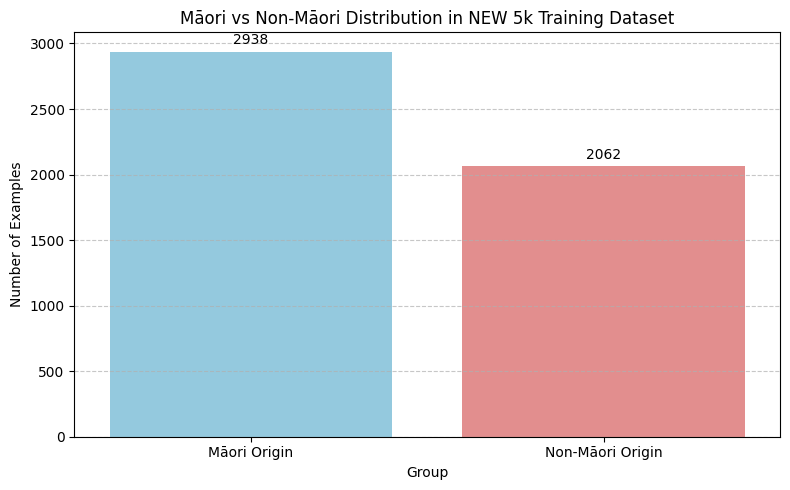

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset # Added for robust loading

# Load the original dataset (redundant if already loaded, but ensures standalone execution)
dataset_name = "dinushiTJ/nz_research_commons_embedding_triplets"
dataset = load_dataset(dataset_name)
train_ds = dataset["train"]
test_ds = dataset["test"]

# Convert train_ds to pandas DataFrame
train_df = train_ds.to_pandas()

TARGET_SIZE = 5000 # Ensure TARGET_SIZE is defined

maori_df = train_df[
    train_df["label"] == "maori_origin"
]

non_maori_df = train_df[
    train_df["label"] != "maori_origin"
]

# Code for sampling (from RMViEO_Gl9l5 to create new_train_df)
remaining = TARGET_SIZE - len(maori_df)

if remaining < 0:
    raise ValueError(
        f"Found {len(maori_df)} Māori samples which exceeds {TARGET_SIZE}."
    )

sampled_non_maori = non_maori_df.sample(
    n=remaining,
    random_state=42
)

new_train_df = pd.concat(
    [maori_df, sampled_non_maori]
)

new_train_df = new_train_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Code for creating df_ethnicity_new (from 7439298a)
new_maori_counts = new_train_df['label'].value_counts()
df_ethnicity_new = pd.DataFrame({
    'Category': ['Māori Origin', 'Non-Māori Origin'],
    'Count': [new_maori_counts.get('maori_origin', 0), new_maori_counts.get('non_maori_origin', 0)]
})

# Plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x='Category',
    y='Count',
    hue='Category', # Assign 'Category' to hue
    data=df_ethnicity_new,
    palette=['skyblue', 'lightcoral'],
    legend=False # Set legend to False as hue is used
)

# Add counts on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

# Titles and labels
plt.title('Māori vs Non-Māori Distribution in NEW 5k Training Dataset')
plt.xlabel('Group')
plt.ylabel('Number of Examples')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
display(df_comparison)

,Dataset,Split,Count
0,Original,Train,10000
1,Original,Test,3318
2,New 5k,Train,5000
3,New 5k,Test,3318


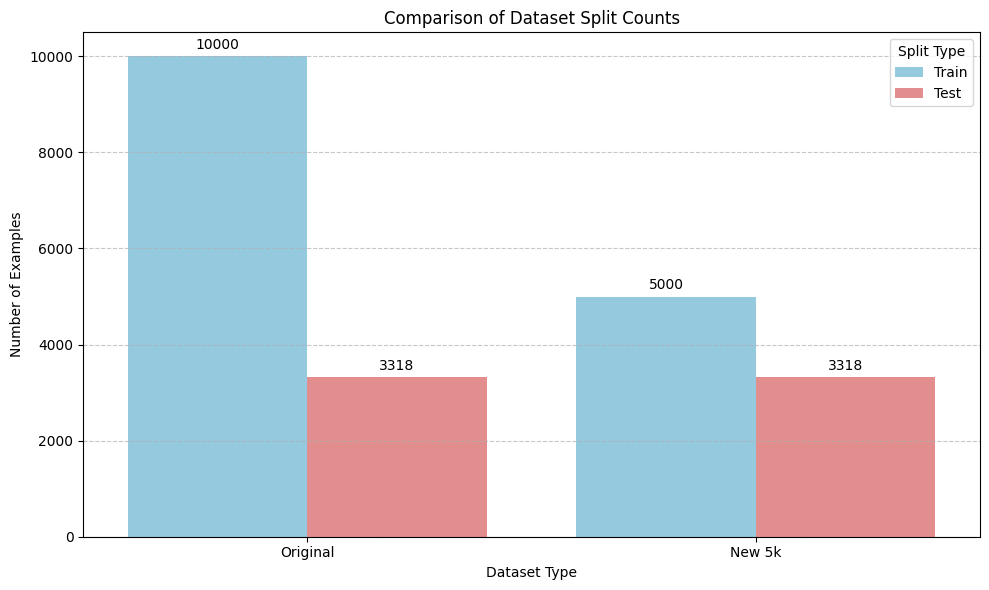

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='Dataset',
    y='Count',
    hue='Split',
    data=df_comparison,
    palette={'Train': 'skyblue', 'Test': 'lightcoral'}
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

# Titles and labels
plt.title('Comparison of Dataset Split Counts')
plt.xlabel('Dataset Type')
plt.ylabel('Number of Examples')

plt.legend(title='Split Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()